In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler, MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

In [ ]:
data = pd.read_csv('/data/data_model_sintetis.csv')

# Tampilkan DataFrame untuk memastikan telah dibaca dengan benar
data.head()

,scenario_id,scenario_profile_metadata,week_start,revenue_7d_idr,expense_7d_idr,cogs_7d_idr,payroll_7d_idr,operating_7d_idr,expense_revenue_ratio,net_operating_margin_proxy_idr,...,revenue_change_vs_previous_week,status_current_week,target_next_week_status,split_group,data_origin,target_definition,source_data_description,currency,label_owner_approved,caution
0,DEMO_CAFE_01,STABLE_LOW_COST,2026-01-05,10037669,4873701,1893828,1204520,1775353,0.485541,5163968,...,0.000000,SEHAT,SEHAT,TRAIN,SIMULATED_DEMO_NOT_GAINCIRCLE,NEXT_WEEK_PROVISIONAL_70_90,coffee revenue pattern + external restaurant c...,IDR,NO,SYNTHETIC FOR PIPELINE ONLY; NOT VERIFIED OWNE...
1,DEMO_CAFE_01,STABLE_LOW_COST,2026-01-12,11367319,4092234,2168884,1364078,559272,0.360000,7275085,...,0.132466,SEHAT,SEHAT,TRAIN,SIMULATED_DEMO_NOT_GAINCIRCLE,NEXT_WEEK_PROVISIONAL_70_90,coffee revenue pattern + external restaurant c...,IDR,NO,SYNTHETIC FOR PIPELINE ONLY; NOT VERIFIED OWNE...
2,DEMO_CAFE_01,STABLE_LOW_COST,2026-01-19,12567510,6269441,3322804,1508101,1438536,0.498861,6298069,...,0.105583,SEHAT,SEHAT,TRAIN,SIMULATED_DEMO_NOT_GAINCIRCLE,NEXT_WEEK_PROVISIONAL_70_90,coffee revenue pattern + external restaurant c...,IDR,NO,SYNTHETIC FOR PIPELINE ONLY; NOT VERIFIED OWNE...
3,DEMO_CAFE_01,STABLE_LOW_COST,2026-01-26,13200873,5272688,2632514,2244148,396026,0.399420,7928185,...,0.050397,SEHAT,SEHAT,TRAIN,SIMULATED_DEMO_NOT_GAINCIRCLE,NEXT_WEEK_PROVISIONAL_70_90,coffee revenue pattern + external restaurant c...,IDR,NO,SYNTHETIC FOR PIPELINE ONLY; NOT VERIFIED OWNE...
4,DEMO_CAFE_01,STABLE_LOW_COST,2026-02-02,12014127,5261382,2788533,1441695,1031154,0.437933,6752745,...,-0.089899,SEHAT,SEHAT,TRAIN,SIMULATED_DEMO_NOT_GAINCIRCLE,NEXT_WEEK_PROVISIONAL_70_90,coffee revenue pattern + external restaurant c...,IDR,NO,SYNTHETIC FOR PIPELINE ONLY; NOT VERIFIED OWNE...


In [4]:
print("\nInformasi dataset:")
data.info()


Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 774 entries, 0 to 773
Data columns (total 23 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   scenario_id                      774 non-null    object 
 1   scenario_profile_metadata        774 non-null    object 
 2   week_start                       774 non-null    object 
 3   revenue_7d_idr                   774 non-null    int64  
 4   expense_7d_idr                   774 non-null    int64  
 5   cogs_7d_idr                      774 non-null    int64  
 6   payroll_7d_idr                   774 non-null    int64  
 7   operating_7d_idr                 774 non-null    int64  
 8   expense_revenue_ratio            774 non-null    float64
 9   net_operating_margin_proxy_idr   774 non-null    int64  
 10  estimated_inventory_waste_pct    774 non-null    float64
 11  payroll_due_within_7d            774 non-null    int64  
 12  we

In [5]:
print("\nMissing values per fitur:")
print(data.isnull().sum())


Missing values per fitur:
scenario_id                        0
scenario_profile_metadata          0
week_start                         0
revenue_7d_idr                     0
expense_7d_idr                     0
cogs_7d_idr                        0
payroll_7d_idr                     0
operating_7d_idr                   0
expense_revenue_ratio              0
net_operating_margin_proxy_idr     0
estimated_inventory_waste_pct      0
payroll_due_within_7d              0
week_of_year                       0
revenue_change_vs_previous_week    0
status_current_week                0
target_next_week_status            0
split_group                        0
data_origin                        0
target_definition                  0
source_data_description            0
currency                           0
label_owner_approved               0
caution                            0
dtype: int64


In [6]:
exclude_columns = [
    'scenario_id', 'scenario_profile_metadata', 'source_data_description',
    'status_current_week', 'data_origin', 'target_definition',
    'label_owner_approved', 'caution', 'week_start', 'currency'
]
split = data['split_group']          # simpan dulu untuk membagi train/val/test
data = data.drop(columns=exclude_columns + ['split_group'])

In [7]:
data['cogs_ratio']      = data['cogs_7d_idr'] / data['revenue_7d_idr']
data['payroll_ratio']   = data['payroll_7d_idr'] / data['revenue_7d_idr']
data['operating_ratio'] = data['operating_7d_idr'] / data['revenue_7d_idr']

In [8]:
data['payroll_x_ratio'] = data['payroll_due_within_7d'] * data['expense_revenue_ratio']


In [9]:
X = data.drop(columns=['target_next_week_status'])
y = data['target_next_week_status']


In [10]:
X_train, y_train = X[split == 'TRAIN'],      y[split == 'TRAIN']
X_val,   y_val   = X[split == 'VALIDATION'], y[split == 'VALIDATION']
X_test,  y_test  = X[split == 'TEST'],       y[split == 'TEST']

In [11]:
data.head()

,revenue_7d_idr,expense_7d_idr,cogs_7d_idr,payroll_7d_idr,operating_7d_idr,expense_revenue_ratio,net_operating_margin_proxy_idr,estimated_inventory_waste_pct,payroll_due_within_7d,week_of_year,revenue_change_vs_previous_week,target_next_week_status,cogs_ratio,payroll_ratio,operating_ratio,payroll_x_ratio
0,10037669,4873701,1893828,1204520,1775353,0.485541,5163968,3.0693,0,2,0.000000,SEHAT,0.188672,0.12,0.176869,0.00000
1,11367319,4092234,2168884,1364078,559272,0.360000,7275085,2.7370,0,3,0.132466,SEHAT,0.190800,0.12,0.049200,0.00000
2,12567510,6269441,3322804,1508101,1438536,0.498861,6298069,2.5172,0,4,0.105583,SEHAT,0.264396,0.12,0.114465,0.00000
3,13200873,5272688,2632514,2244148,396026,0.399420,7928185,2.6545,1,5,0.050397,SEHAT,0.199420,0.17,0.030000,0.39942
4,12014127,5261382,2788533,1441695,1031154,0.437933,6752745,2.1381,0,6,-0.089899,SEHAT,0.232105,0.12,0.085828,0.00000


In [13]:
data = data.drop(columns=['payroll_ratio'])

In [14]:
print(data.shape)                     # harusnya (774, 15): 11 fitur asli + 3 fitur baru + target
print(data.isna().sum().sum())        # harusnya 0
print(data['target_next_week_status'].value_counts())

(774, 15)
0
target_next_week_status
KRITIS     278
SEHAT      274
WASPADA    222
Name: count, dtype: int64


In [15]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix

# Buat ulang X, y, dan split (payroll_ratio sudah dihapus)
X = data.drop(columns=['target_next_week_status'])
y = data['target_next_week_status']

X_train, y_train = X[split == 'TRAIN'],      y[split == 'TRAIN']
X_val,   y_val   = X[split == 'VALIDATION'], y[split == 'VALIDATION']
X_test,  y_test  = X[split == 'TEST'],       y[split == 'TEST']

models = {
    'Random Forest': RandomForestClassifier(
        n_estimators=300, class_weight='balanced', random_state=42),
    'Logistic Regression': make_pipeline(
        StandardScaler(),   # scaler di-fit hanya pada X_train lewat pipeline
        LogisticRegression(max_iter=2000, class_weight='balanced')),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_val)
    print(f'=== {name} (VALIDATION) ===')
    print(classification_report(y_val, pred, digits=3))
    print(confusion_matrix(y_val, pred, labels=['SEHAT', 'WASPADA', 'KRITIS']))

=== Random Forest (VALIDATION) ===
              precision    recall  f1-score   support

      KRITIS      0.804     0.837     0.820        49
       SEHAT      0.863     0.898     0.880        49
     WASPADA      0.556     0.484     0.517        31

    accuracy                          0.775       129
   macro avg      0.741     0.740     0.739       129
weighted avg      0.767     0.775     0.770       129

[[44  4  1]
 [ 7 15  9]
 [ 0  8 41]]
=== Logistic Regression (VALIDATION) ===
              precision    recall  f1-score   support

      KRITIS      0.765     0.796     0.780        49
       SEHAT      0.880     0.898     0.889        49
     WASPADA      0.500     0.452     0.475        31

    accuracy                          0.752       129
   macro avg      0.715     0.715     0.714       129
weighted avg      0.745     0.752     0.748       129

[[44  4  1]
 [ 6 14 11]
 [ 0 10 39]]


In [18]:
final_model = RandomForestClassifier(
    n_estimators=300, max_depth=4, max_features=0.5,
    class_weight={'SEHAT': 1, 'WASPADA': 1.5, 'KRITIS': 1},
    random_state=42)
final_model.fit(X_train, y_train)

pred_val = final_model.predict(X_val)
print('=== Model Final (VALIDATION) ===')
print(classification_report(y_val, pred_val, digits=3))
print(confusion_matrix(y_val, pred_val, labels=['SEHAT', 'WASPADA', 'KRITIS']))

=== Model Final (VALIDATION) ===
              precision    recall  f1-score   support

      KRITIS      0.860     0.755     0.804        49
       SEHAT      0.915     0.878     0.896        49
     WASPADA      0.564     0.710     0.629        31

    accuracy                          0.791       129
   macro avg      0.780     0.781     0.776       129
weighted avg      0.810     0.791     0.797       129

[[43  5  1]
 [ 4 22  5]
 [ 0 12 37]]


In [19]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import f1_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
f1_train = f1_score(y_train, final_model.predict(X_train), average='macro')
f1_cv    = cross_val_score(final_model, X_train, y_train, cv=cv, scoring='f1_macro').mean()
f1_val   = f1_score(y_val, pred_val, average='macro')

print(f'F1 Train     : {f1_train:.3f}')
print(f'F1 CV        : {f1_cv:.3f}')
print(f'F1 Validation: {f1_val:.3f}')
print(f'Gap Train-CV : {f1_train - f1_cv:.3f}')   # < 0.10 = overfitting ringan/terkendali

F1 Train     : 0.823
F1 CV        : 0.729
F1 Validation: 0.776
Gap Train-CV : 0.094


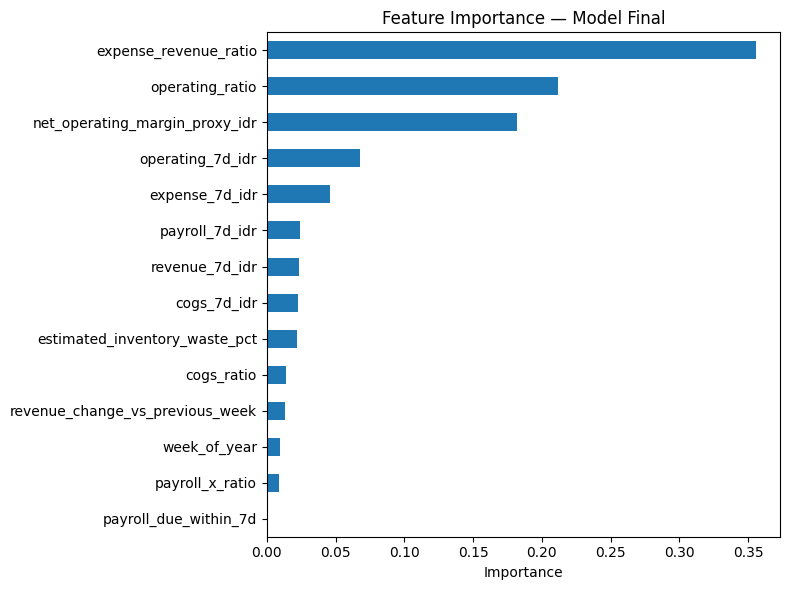

In [20]:
import matplotlib.pyplot as plt

importance = pd.Series(final_model.feature_importances_, index=X_train.columns).sort_values()
importance.plot(kind='barh', figsize=(8, 6), title='Feature Importance — Model Final')
plt.xlabel('Importance'); plt.tight_layout(); plt.show()

In [21]:
pred_test = final_model.predict(X_test)
print('=== Model Final (TEST) ===')
print(classification_report(y_test, pred_test, digits=3))
print(confusion_matrix(y_test, pred_test, labels=['SEHAT', 'WASPADA', 'KRITIS']))

=== Model Final (TEST) ===
              precision    recall  f1-score   support

      KRITIS      0.703     0.703     0.703        37
       SEHAT      0.891     0.837     0.863        49
     WASPADA      0.609     0.651     0.629        43

    accuracy                          0.736       129
   macro avg      0.734     0.730     0.732       129
weighted avg      0.743     0.736     0.739       129

[[41  8  0]
 [ 4 28 11]
 [ 1 10 26]]


In [22]:
import joblib

artifact = {
    'model': final_model,
    'feature_columns': list(X_train.columns),
    'engineered_features': {
        'net_operating_margin_proxy_idr': 'revenue_7d_idr - expense_7d_idr',
        'cogs_ratio':      'cogs_7d_idr / revenue_7d_idr',
        'operating_ratio': 'operating_7d_idr / revenue_7d_idr',
        'payroll_x_ratio': 'payroll_due_within_7d * expense_revenue_ratio',
    },
    'target': 'target_next_week_status',
    'classes': list(final_model.classes_),
    'model_version': 'rf_demo_v0.1',
    'data_origin': 'SIMULATED_DEMO_NOT_GAINCIRCLE',
    'owner_rule_approved': False,
}
joblib.dump(artifact, 'model_rf_demo_v0.1.joblib')

from google.colab import files
files.download('model_rf_demo_v0.1.joblib')   # unduh ke komputer

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
def predict_status(request: dict, artifact: dict) -> dict:
    required = ['revenue_7d_idr', 'expense_7d_idr', 'cogs_7d_idr', 'payroll_7d_idr',
                'operating_7d_idr', 'expense_revenue_ratio', 'estimated_inventory_waste_pct',
                'payroll_due_within_7d', 'week_of_year', 'revenue_change_vs_previous_week']

    # Data belum lengkap → sesuai missing_data_response di kontrak
    if any(request.get(k) is None for k in required) or not request.get('revenue_7d_idr'):
        return {'status': 'BELUM_ADA_DATA', 'assessment_type': 'NO_ASSESSMENT',
                'reason': 'Data pemasukan/pengeluaran periode belum lengkap', 'currency': 'IDR'}

    r = dict(request)
    r['net_operating_margin_proxy_idr'] = r['revenue_7d_idr'] - r['expense_7d_idr']
    r['cogs_ratio']      = r['cogs_7d_idr'] / r['revenue_7d_idr']
    r['operating_ratio'] = r['operating_7d_idr'] / r['revenue_7d_idr']
    r['payroll_x_ratio'] = r['payroll_due_within_7d'] * r['expense_revenue_ratio']

    x = pd.DataFrame([r])[artifact['feature_columns']]
    model = artifact['model']
    proba = dict(zip(model.classes_, model.predict_proba(x)[0].round(3)))
    status = model.predict(x)[0]

    return {
        'status': status,
        'assessment_type': 'ML_MODEL_DEMO',
        'probabilities': proba,
        'explanation': f"Prediksi status minggu depan: {status} "
                       f"(rasio biaya terhadap pendapatan {r['expense_revenue_ratio']:.0%}).",
        'owner_rule_approved': artifact['owner_rule_approved'],
        'model_version': artifact['model_version'],
        'currency': 'IDR',
        'data_origin': request.get('data_origin', 'DEMO_INPUT'),
    }

request_example = {
    'business_id': 'GAIN_CIRCLE_DEMO', 'week_start': '2026-11-16',
    'revenue_7d_idr': 9600000, 'expense_7d_idr': 7872000, 'cogs_7d_idr': 3168000,
    'payroll_7d_idr': 1920000, 'operating_7d_idr': 2784000,
    'expense_revenue_ratio': 0.82, 'estimated_inventory_waste_pct': 2.4,
    'payroll_due_within_7d': 0, 'week_of_year': 47,
    'revenue_change_vs_previous_week': 0.06, 'data_origin': 'DEMO_INPUT',
}

loaded = joblib.load('model_rf_demo_v0.1.joblib')
predict_status(request_example, loaded)

{'status': 'WASPADA',
 'assessment_type': 'ML_MODEL_DEMO',
 'probabilities': {'KRITIS': np.float64(0.105),
  'SEHAT': np.float64(0.233),
  'WASPADA': np.float64(0.663)},
 'explanation': 'Prediksi status minggu depan: WASPADA (rasio biaya terhadap pendapatan 82%).',
 'owner_rule_approved': False,
 'model_version': 'rf_demo_v0.1',
 'currency': 'IDR',
 'data_origin': 'DEMO_INPUT'}